In [1]:
!pip install ucimlrepo


   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 343.6 kB/s eta 0:00:31
   - -------------------------------------- 0.5/10.9 MB 343.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   --- ------------------------------------ 1


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Load medical dataset
medical = fetch_ucirepo(id=161)

# Separate features and target
X = medical.data.features.copy()
y = medical.data.targets.copy()

# Combine dataset
df = pd.concat([X, y], axis=1)

# Rename columns
df.columns = ['BI-RADS', 'Age', 'Shape',
              'Margin', 'Density', 'Severity']

# Replace missing value symbols
df.replace('?', np.nan, inplace=True)

print("Medical Diagnostics Dataset Loaded Successfully!")
print(df.head())

Medical Diagnostics Dataset Loaded Successfully!
   BI-RADS   Age  Shape  Margin  Density  Severity
0      5.0  67.0    3.0     5.0      3.0         1
1      4.0  43.0    1.0     1.0      NaN         1
2      5.0  58.0    4.0     5.0      3.0         1
3      4.0  28.0    1.0     1.0      3.0         0
4      5.0  74.0    1.0     5.0      NaN         1


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (961, 6)

First 5 Records:
   BI-RADS   Age  Shape  Margin  Density  Severity
0      5.0  67.0    3.0     5.0      3.0         1
1      4.0  43.0    1.0     1.0      NaN         1
2      5.0  58.0    4.0     5.0      3.0         1
3      4.0  28.0    1.0     1.0      3.0         0
4      5.0  74.0    1.0     5.0      NaN         1

Column Names:
Index(['BI-RADS', 'Age', 'Shape', 'Margin', 'Density', 'Severity'], dtype='str')

Data Types:
BI-RADS     float64
Age         float64
Shape       float64
Margin      float64
Density     float64
Severity      int64
dtype: object

Missing Values:
BI-RADS      2
Age          5
Shape       31
Margin      48
Density     76
Severity     0
dtype: int64


In [4]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

BI-RADS     float64
Age         float64
Shape       float64
Margin      float64
Density     float64
Severity      int64
dtype: object

Missing Values:
BI-RADS      2
Age          5
Shape       31
Margin      48
Density     76
Severity     0
dtype: int64


In [5]:
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
          BI-RADS         Age       Shape      Margin     Density    Severity
count  959.000000  956.000000  930.000000  913.000000  885.000000  961.000000
mean     4.348279   55.487448    2.721505    2.796276    2.910734    0.463059
std      1.783031   14.480131    1.242792    1.566546    0.380444    0.498893
min      0.000000   18.000000    1.000000    1.000000    1.000000    0.000000
25%      4.000000   45.000000    2.000000    1.000000    3.000000    0.000000
50%      4.000000   57.000000    3.000000    3.000000    3.000000    0.000000
75%      5.000000   66.000000    4.000000    4.000000    3.000000    1.000000
max     55.000000   96.000000    4.000000    5.000000    4.000000    1.000000


In [8]:
from sklearn.model_selection import train_test_split

# Select input features
X = df[['Age', 'Shape', 'Margin', 'Density']]

# Select target column
y = df['Severity']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (768, 4)
Testing data: (193, 4)
Training target: (768,)
Testing target: (193,)


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [9]:
numeric_features = ['Age']

categorical_features = ['Shape', 'Margin', 'Density']

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Age']
Categorical Features: ['Shape', 'Margin', 'Density']


In [10]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [11]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [12]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("ColumnTransformer Created Successfully!")

ColumnTransformer Created Successfully!


In [16]:
final_pipeline = Pipeline([
    ('preprocessing', preprocessor)
])

# Fit only training data
X_train_processed = final_pipeline.fit_transform(X_train)

# Transform testing data
X_test_processed = final_pipeline.transform(X_test)

print("Preprocessing Completed Successfully!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Preprocessing Completed Successfully!
Training Data Shape: (768, 14)
Testing Data Shape: (193, 14)


In [17]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization Libraries Imported Successfully!")

Matplotlib is building the font cache; this may take a moment.


Visualization Libraries Imported Successfully!


In [19]:
correlation = df[
    ['Age', 'Shape', 'Margin', 'Density', 'Severity']
].corr()

print(correlation)

               Age     Shape    Margin   Density  Severity
Age       1.000000  0.364077  0.411355  0.028954  0.432066
Shape     0.364077  1.000000  0.742211  0.078666  0.563308
Margin    0.411355  0.742211  1.000000  0.109392  0.574919
Density   0.028954  0.078666  0.109392  1.000000  0.064010
Severity  0.432066  0.563308  0.574919  0.064010  1.000000


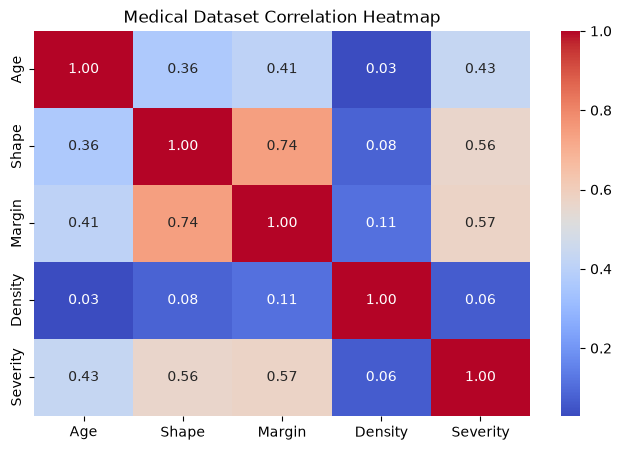

In [20]:
plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Medical Dataset Correlation Heatmap")
plt.show()

In [21]:
from sklearn.feature_selection import mutual_info_classif

import pandas as pd

In [22]:
# Convert processed data into dense format
X_train_dense = X_train_processed.toarray()

# Identify categorical features
feature_names = final_pipeline.named_steps[
    'preprocessing'
].get_feature_names_out()

discrete_mask = [
    name.startswith('cat__') for name in feature_names
]

# Calculate mutual information
importance = mutual_info_classif(
    X_train_dense,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Create importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

print(importance_df)

             Feature  Importance
5    cat__Margin_1.0    0.182429
4     cat__Shape_4.0    0.147646
0           num__Age    0.115051
1     cat__Shape_1.0    0.058903
2     cat__Shape_2.0    0.050027
9    cat__Margin_5.0    0.046774
8    cat__Margin_4.0    0.045458
7    cat__Margin_3.0    0.010014
11  cat__Density_2.0    0.003963
12  cat__Density_3.0    0.002971
6    cat__Margin_2.0    0.000194
3     cat__Shape_3.0    0.000106
13  cat__Density_4.0    0.000009
10  cat__Density_1.0    0.000002


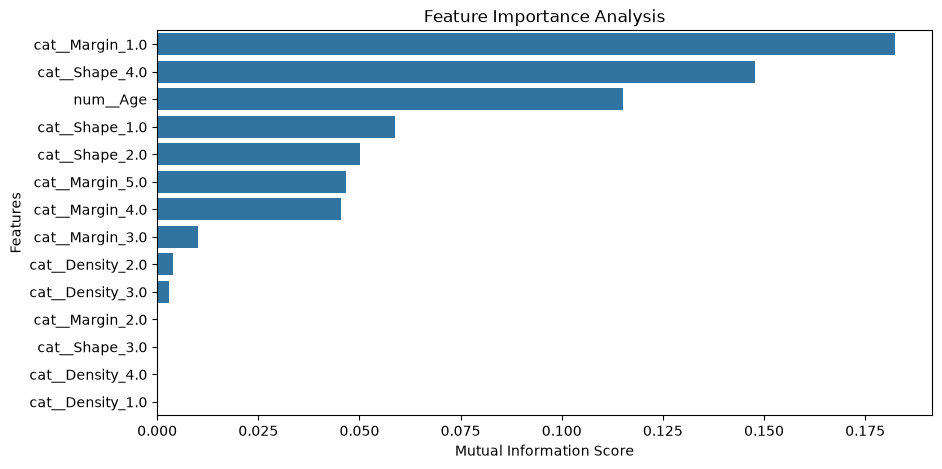

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance Analysis")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.show()

In [24]:
print("FINAL PIPELINE VERIFICATION")

print("Training Data:", X_train_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("Missing Values in Training:",
      np.isnan(X_train_processed.toarray()).sum())

print("Missing Values in Testing:",
      np.isnan(X_test_processed.toarray()).sum())

print("\nPreprocessing Completed Successfully!")

FINAL PIPELINE VERIFICATION
Training Data: (768, 14)
Testing Data: (193, 14)
Missing Values in Training: 0
Missing Values in Testing: 0

Preprocessing Completed Successfully!
